In [ ]:
# terminal: convert to html excluding code blocks
##### jupyter nbconvert documents/05-26.ipynb --no-input --to html

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
log_dir = 'RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_stepce/'

##### Changes
- Entropy coefficient is decreasing stepwise. It starts with a big value for encouraging exploration. It decreases with time for exploitation
- The previous trained model's sensing performance is worse compared to the benchmark method
The currect training model has a higher weight on the sensing performance. 

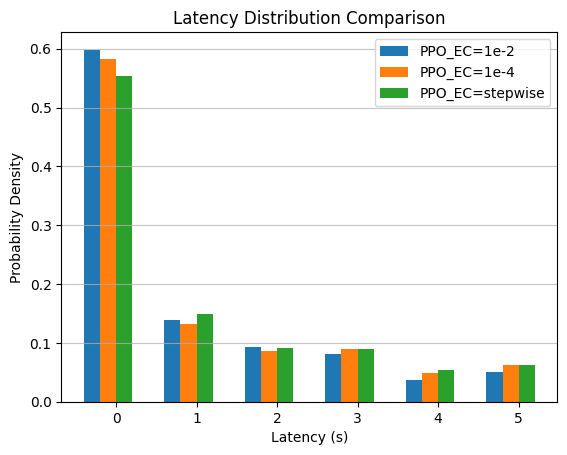

In [3]:
## Compared between stepwise entropy coefficient and constant entropy coefficient
def load_latency(log_dir, filename):
    data = pd.read_csv(log_dir + filename, skiprows=0)
    data1 = list(itertools.chain(*data.values))
    data2 = [x for x in data1 if x != -1]
    return data2

latency_stepwise = load_latency(log_dir, 'trained/latency.csv')
latency_constant_2 = load_latency('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_ce-2/', 'trained/latency.csv')
latency_constant_4 = load_latency('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_ce-4/', 'trained/latency.csv')
latency_diffLatency = load_latency('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newBuffer_diffLatency/', 'trained/latency.csv')

figure_handle = plt.figure()
ax2 = figure_handle.add_subplot()

counts_2, bins_2, _ = ax2.hist(latency_constant_2, bins=range(7), density=True, alpha=0.7)
counts_4, bins_4, _ = ax2.hist(latency_constant_4, bins=range(7), density=True, alpha=0.7)
counts_stepwise, bins_stepwise, _ = ax2.hist(latency_stepwise, bins=range(7), density=True, alpha=0.7)
counts_diffLatency, bins_diffLatency, _ = ax2.hist(latency_diffLatency, bins=range(7), density=True, alpha=0.7)


bin_center = (bins_2[:-1] + bins_2[1:]) / 2
ax2.cla()
ax2.bar(bin_center-0.3, counts_2, width=0.2, label='PPO_EC=1e-2', align='center')
ax2.bar(bin_center - 0.1, counts_4, width=0.2, label='PPO_EC=1e-4', align='center')
ax2.bar(bin_center + 0.1, counts_stepwise, width=0.2, label='PPO_EC=stepwise', align='center')
# ax2.bar(bin_center + 0.3, counts_diffLatency, width=0.2, label='PPO_EC=diffLatency', align='center')

ax2.set_xlabel('Latency (s)')
ax2.set_ylabel('Probability Density')
ax2.set_title('Latency Distribution Comparison')   
ax2.legend()
ax2.set_xticks(bin_center)
ax2.set_xticklabels(range(6))
plt.grid(axis='y', alpha=0.75)
ax2.legend()
plt.show()

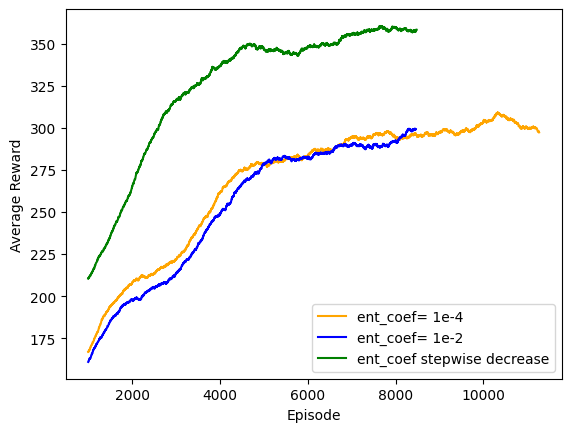

In [4]:
monitor_file = "RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_ce-4/monitor.csv"
# MONITOR_95 is temporary file for testing. It is still running
monitor_data = pd.read_csv(monitor_file, skiprows=1)

window_size = 1000
moving_average_4 = monitor_data['r'].rolling(window=window_size).mean().dropna()

monitor_file = "RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_ce-2/monitor_1.csv"
# MONITOR_95 is temporary file for testing. It is still running
monitor_data = pd.read_csv(monitor_file, skiprows=1)

window_size = 1000
moving_average_2 = monitor_data['r'].rolling(window=window_size).mean().dropna()

monitor_file = "RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_sense_stepce/monitor_0.csv"
# MONITOR_95 is temporary file for testing. It is still running
monitor_data = pd.read_csv(monitor_file, skiprows=1)

window_size = 1000
moving_average_step = monitor_data['r'].rolling(window=window_size).mean().dropna()

fig, ax = plt.subplots()
ax.plot(moving_average_4, label='ent_coef= 1e-4', color='orange')
ax.plot(moving_average_2, label='ent_coef= 1e-2', color='blue')
ax.plot(moving_average_step, label='ent_coef stepwise decrease', color='green')
ax.set_xlabel('Episode')
ax.set_ylabel('Average Reward')
ax.legend()

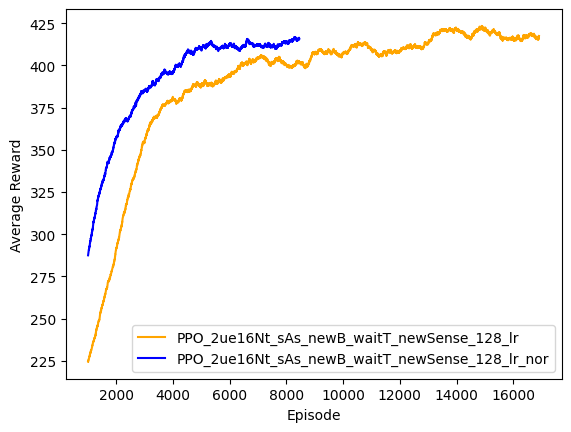

In [7]:
## Compare between PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr and PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr_nor
monitor_file = "RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr/monitor_0.csv"
monitor_data = pd.read_csv(monitor_file, skiprows=0)
window_size = 1000
moving_average_128 = monitor_data['r'].rolling(window=window_size).mean().dropna()
monitor_file = "RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr_nor/monitor.csv"
monitor_data = pd.read_csv(monitor_file, skiprows=1)
window_size = 1000
moving_average_128_nor = monitor_data['r'].rolling(window=window_size).mean().dropna()
fig, ax = plt.subplots()
ax.plot(moving_average_128, label='PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr', color='orange')
ax.plot(moving_average_128_nor, label='PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr_nor', color='blue')
ax.set_xlabel('Episode')
ax.set_ylabel('Average Reward')
ax.legend()


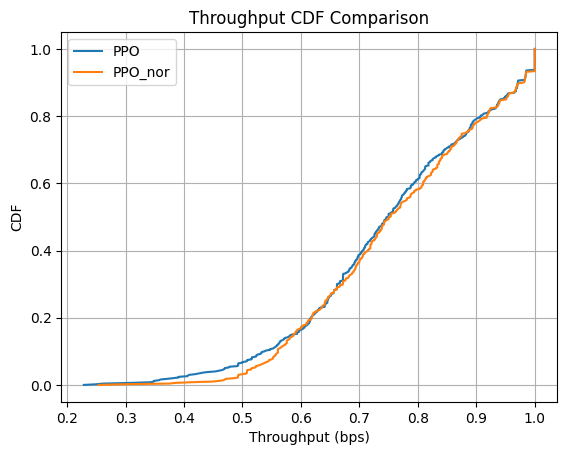

In [12]:
# compare their throughput's CDF

throughput_128 = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr/trained/throughput.csv', skiprows=0)
throughput_128_nor = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr_nor/trained/throughput.csv', skiprows=0)
figure_handle = plt.figure()
ax2 = figure_handle.add_subplot()

thp_cdf = np.sort(throughput_128['Throughput'])
yvals = np.arange(len(thp_cdf))/float(len(thp_cdf)-1)
ax2.plot(thp_cdf, yvals, '-', label='PPO')
thp_cdf_nor = np.sort(throughput_128_nor['Throughput'])
yvals_nor = np.arange(len(thp_cdf_nor))/float(len(thp_cdf_nor)-1)
ax2.plot(thp_cdf_nor, yvals_nor, '-', label='PPO_nor')
ax2.set_xlabel('Throughput (bps)')
ax2.set_ylabel('CDF')
ax2.set_title('Throughput CDF Comparison')
ax2.legend()
plt.grid()


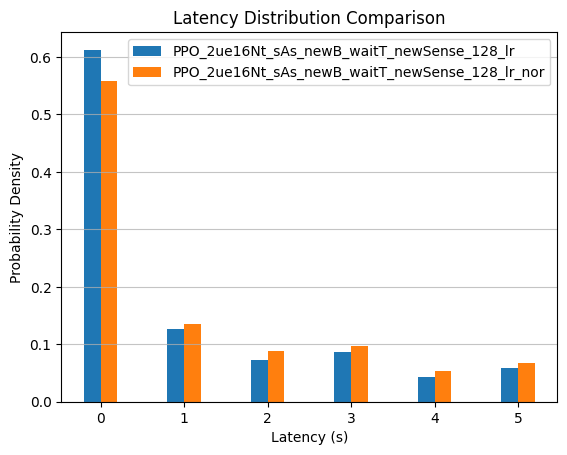

In [14]:
# compare their latency 
latency_128 = load_latency('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr/trained/','latency.csv')
latency_128_nor = load_latency('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr_nor/trained/','latency.csv')
figure_handle = plt.figure()
ax2 = figure_handle.add_subplot()
counts_128, bins_128, _ = ax2.hist(latency_128, bins=range(7), density=True, alpha=0.7)
counts_128_nor, bins_128_nor, _ = ax2.hist(latency_128_nor, bins=range(7), density=True, alpha=0.7)
bin_center_128 = (bins_128[:-1] + bins_128[1:]) / 2
ax2.cla()
ax2.bar(bin_center_128-0.1, counts_128, width=0.2, label='PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr', align='center')
ax2.bar(bin_center_128 + 0.1, counts_128_nor, width=0.2, label='PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr_nor', align='center')
ax2.set_xlabel('Latency (s)')
ax2.set_ylabel('Probability Density')
ax2.set_title('Latency Distribution Comparison')
ax2.legend()
ax2.set_xticks(bin_center_128)
ax2.set_xticklabels(range(6))
plt.grid(axis='y', alpha=0.75)
ax2.legend()
plt.show()

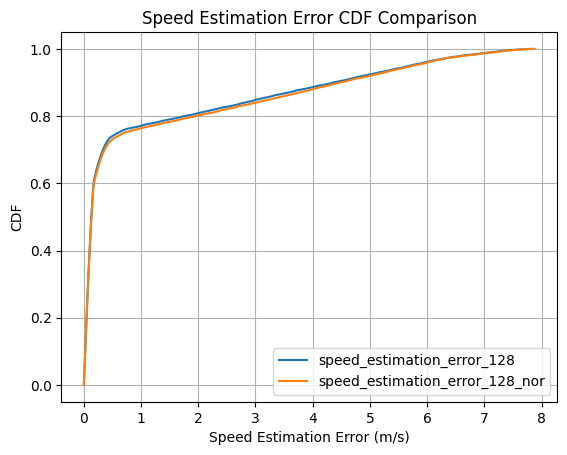

In [18]:
# compare speed estimation error
speed_estimation_error_128 = np.array(pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr/trained/nmseV_allsteps.csv', skiprows=1))
speed_estimation_error_128_nor = np.array(pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_sAs_newB_waitT_newSense_128_lr_nor/trained/nmseV_allsteps.csv', skiprows=1))
figure_handle = plt.figure()
ax2 = figure_handle.add_subplot()

err_cdf = np.sort(speed_estimation_error_128.flatten())
yvals = np.arange(len(err_cdf))/float(len(err_cdf)-1)
ax2.plot(err_cdf, yvals, '-', label='speed_estimation_error_128')
err_cdf_nor = np.sort(speed_estimation_error_128_nor.flatten())
yvals_nor = np.arange(len(err_cdf_nor))/float(len(err_cdf_nor)-1)
ax2.plot(err_cdf_nor, yvals_nor, '-', label='speed_estimation_error_128_nor')
ax2.set_xlabel('Speed Estimation Error (m/s)')
ax2.set_ylabel('CDF')
ax2.set_title('Speed Estimation Error CDF Comparison')
ax2.legend()
plt.grid()
